In [21]:
import pandas as pd
import numpy as np
import random

df = pd.DataFrame([
    [6.82, 118,0],
    [6.36, 125, 1],
    [5.39, 99,1],
    [5.50, 106, 1],
    [6.39, 148, 1],
    [9.13, 148,1],
    [7.17, 147, 1],
    [7.72, 72, 0]
],columns=['cgpa','iq','is_placed'])

df

,cgpa,iq,is_placed
0,6.82,118,0
1,6.36,125,1
2,5.39,99,1
3,5.50,106,1
4,6.39,148,1
5,9.13,148,1
6,7.17,147,1
7,7.72,72,0


In [22]:
# inital prediciton
df['pre1(log-odds)'] = np.log(5/3)

# convert log odds to probability
df['pre1(probability)'] = 1 / (1+np.exp(-np.log(5/3)))
df

,cgpa,iq,is_placed,pre1(log-odds),pre1(probability)
0,6.82,118,0,0.510826,0.625
1,6.36,125,1,0.510826,0.625
2,5.39,99,1,0.510826,0.625
3,5.50,106,1,0.510826,0.625
4,6.39,148,1,0.510826,0.625
5,9.13,148,1,0.510826,0.625
6,7.17,147,1,0.510826,0.625
7,7.72,72,0,0.510826,0.625


In [23]:
# calculating residual for stage 1
df['res1'] = df['is_placed'] - df['pre1(probability)']

df

,cgpa,iq,is_placed,pre1(log-odds),pre1(probability),res1
0,6.82,118,0,0.510826,0.625,-0.625
1,6.36,125,1,0.510826,0.625,0.375
2,5.39,99,1,0.510826,0.625,0.375
3,5.50,106,1,0.510826,0.625,0.375
4,6.39,148,1,0.510826,0.625,0.375
5,9.13,148,1,0.510826,0.625,0.375
6,7.17,147,1,0.510826,0.625,0.375
7,7.72,72,0,0.510826,0.625,-0.625


In [24]:
# training the first decision tree
from sklearn.tree import DecisionTreeRegressor

reg1 = DecisionTreeRegressor(max_leaf_nodes= 3, random_state=1)

reg1.fit(df.iloc[:,0:2].values, df.iloc[:,-1].values)

DecisionTreeRegressor(max_leaf_nodes=3, random_state=1)

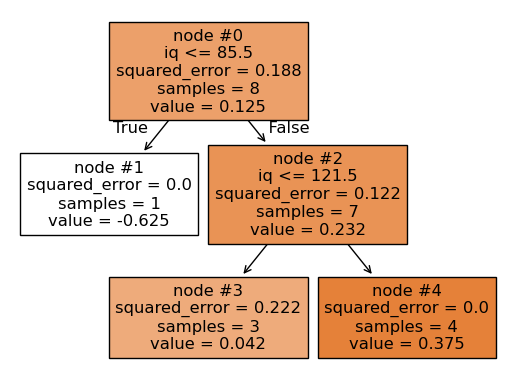

In [25]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plot_tree(reg1, feature_names = ['cgpa', 'iq'], filled =True, node_ids=True)
plt.show()

In [26]:
df['leaf_entry1'] = reg1.apply(df.iloc[:,0:2])
df

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(


,cgpa,iq,is_placed,pre1(log-odds),pre1(probability),res1,leaf_entry1
0,6.82,118,0,0.510826,0.625,-0.625,3
1,6.36,125,1,0.510826,0.625,0.375,4
2,5.39,99,1,0.510826,0.625,0.375,3
3,5.50,106,1,0.510826,0.625,0.375,3
4,6.39,148,1,0.510826,0.625,0.375,4
5,9.13,148,1,0.510826,0.625,0.375,4
6,7.17,147,1,0.510826,0.625,0.375,4
7,7.72,72,0,0.510826,0.625,-0.625,1


In [27]:
def return_logs(leaf):
  temp_df = df[df['leaf_entry1'] == leaf]
  num = temp_df['res1'].sum()

  den = sum(temp_df['pre1(probability)'] * (1-temp_df['pre1(probability)']))

  return round(num/den,2)

In [28]:
df['pre2(log-odds)'] = df['pre1(log-odds)'] + df['leaf_entry1'].apply(return_logs)

In [29]:
df['pre2(probability)'] = 1/ (1+np.exp(-df['pre2(log-odds)']))
df

,cgpa,iq,is_placed,pre1(log-odds),pre1(probability),res1,leaf_entry1,pre2(log-odds),pre2(probability)
0,6.82,118,0,0.510826,0.625,-0.625,3,0.690826,0.666151
1,6.36,125,1,0.510826,0.625,0.375,4,2.110826,0.891951
2,5.39,99,1,0.510826,0.625,0.375,3,0.690826,0.666151
3,5.50,106,1,0.510826,0.625,0.375,3,0.690826,0.666151
4,6.39,148,1,0.510826,0.625,0.375,4,2.110826,0.891951
5,9.13,148,1,0.510826,0.625,0.375,4,2.110826,0.891951
6,7.17,147,1,0.510826,0.625,0.375,4,2.110826,0.891951
7,7.72,72,0,0.510826,0.625,-0.625,1,-2.159174,0.103477


In [30]:
df['res2'] = df['is_placed'] - df['pre2(probability)']
df

,cgpa,iq,is_placed,pre1(log-odds),pre1(probability),res1,leaf_entry1,pre2(log-odds),pre2(probability),res2
0,6.82,118,0,0.510826,0.625,-0.625,3,0.690826,0.666151,-0.666151
1,6.36,125,1,0.510826,0.625,0.375,4,2.110826,0.891951,0.108049
2,5.39,99,1,0.510826,0.625,0.375,3,0.690826,0.666151,0.333849
3,5.50,106,1,0.510826,0.625,0.375,3,0.690826,0.666151,0.333849
4,6.39,148,1,0.510826,0.625,0.375,4,2.110826,0.891951,0.108049
5,9.13,148,1,0.510826,0.625,0.375,4,2.110826,0.891951,0.108049
6,7.17,147,1,0.510826,0.625,0.375,4,2.110826,0.891951,0.108049
7,7.72,72,0,0.510826,0.625,-0.625,1,-2.159174,0.103477,-0.103477


In [31]:
reg2 = DecisionTreeRegressor(max_leaf_nodes= 3, random_state=1)

reg2.fit(df.iloc[:,0:2].values, df.iloc[:,-1].values)

DecisionTreeRegressor(max_leaf_nodes=3, random_state=1)

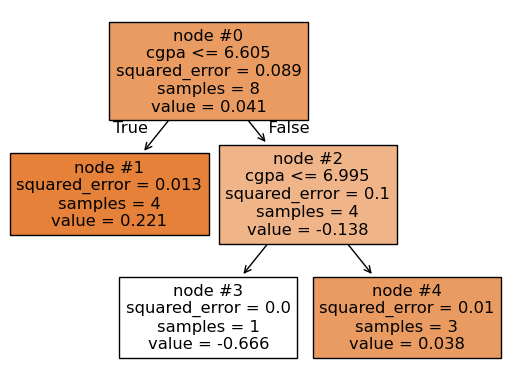

In [32]:
plot_tree(reg2, feature_names= ['cgpa','iq'],filled=True, node_ids= True)
plt.show()

In [33]:
df['leaf_entry2'] = reg2.apply(df.iloc[:,0:2])
df

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(


,cgpa,iq,is_placed,pre1(log-odds),pre1(probability),res1,leaf_entry1,pre2(log-odds),pre2(probability),res2,leaf_entry2
0,6.82,118,0,0.510826,0.625,-0.625,3,0.690826,0.666151,-0.666151,3
1,6.36,125,1,0.510826,0.625,0.375,4,2.110826,0.891951,0.108049,1
2,5.39,99,1,0.510826,0.625,0.375,3,0.690826,0.666151,0.333849,1
3,5.50,106,1,0.510826,0.625,0.375,3,0.690826,0.666151,0.333849,1
4,6.39,148,1,0.510826,0.625,0.375,4,2.110826,0.891951,0.108049,1
5,9.13,148,1,0.510826,0.625,0.375,4,2.110826,0.891951,0.108049,4
6,7.17,147,1,0.510826,0.625,0.375,4,2.110826,0.891951,0.108049,4
7,7.72,72,0,0.510826,0.625,-0.625,1,-2.159174,0.103477,-0.103477,4


In [34]:
def return_logs(leaf):
  num = df[df['leaf_entry2'] == leaf]['res2'].sum()
  den = sum(df[df['leaf_entry2'] == leaf]['pre2(probability)'] * (1-df[df['leaf_entry2'] == leaf]['pre2(probability)']))

  return round(num/den,2)

In [35]:
df['pre3(log-odds)'] = df['pre2(log-odds)'] + df['leaf_entry2'].apply(return_logs)
df

,cgpa,iq,is_placed,pre1(log-odds),pre1(probability),res1,leaf_entry1,pre2(log-odds),pre2(probability),res2,leaf_entry2,pre3(log-odds)
0,6.82,118,0,0.510826,0.625,-0.625,3,0.690826,0.666151,-0.666151,3,-2.309174
1,6.36,125,1,0.510826,0.625,0.375,4,2.110826,0.891951,0.108049,1,3.500826
2,5.39,99,1,0.510826,0.625,0.375,3,0.690826,0.666151,0.333849,1,2.080826
3,5.50,106,1,0.510826,0.625,0.375,3,0.690826,0.666151,0.333849,1,2.080826
4,6.39,148,1,0.510826,0.625,0.375,4,2.110826,0.891951,0.108049,1,3.500826
5,9.13,148,1,0.510826,0.625,0.375,4,2.110826,0.891951,0.108049,4,2.500826
6,7.17,147,1,0.510826,0.625,0.375,4,2.110826,0.891951,0.108049,4,2.500826
7,7.72,72,0,0.510826,0.625,-0.625,1,-2.159174,0.103477,-0.103477,4,-1.769174


In [36]:
df['pre3(probability)'] = 1/(1+np.exp(-df['pre3(log-odds)']))
df

,cgpa,iq,is_placed,pre1(log-odds),pre1(probability),res1,leaf_entry1,pre2(log-odds),pre2(probability),res2,leaf_entry2,pre3(log-odds),pre3(probability)
0,6.82,118,0,0.510826,0.625,-0.625,3,0.690826,0.666151,-0.666151,3,-2.309174,0.090366
1,6.36,125,1,0.510826,0.625,0.375,4,2.110826,0.891951,0.108049,1,3.500826,0.970711
2,5.39,99,1,0.510826,0.625,0.375,3,0.690826,0.666151,0.333849,1,2.080826,0.889026
3,5.50,106,1,0.510826,0.625,0.375,3,0.690826,0.666151,0.333849,1,2.080826,0.889026
4,6.39,148,1,0.510826,0.625,0.375,4,2.110826,0.891951,0.108049,1,3.500826,0.970711
5,9.13,148,1,0.510826,0.625,0.375,4,2.110826,0.891951,0.108049,4,2.500826,0.924200
6,7.17,147,1,0.510826,0.625,0.375,4,2.110826,0.891951,0.108049,4,2.500826,0.924200
7,7.72,72,0,0.510826,0.625,-0.625,1,-2.159174,0.103477,-0.103477,4,-1.769174,0.145645


In [37]:
df['res_final'] = df['is_placed'] - df['pre3(probability)']
df[['res1','res2','res_final']]

,res1,res2,res_final
0,-0.625,-0.666151,-0.090366
1,0.375,0.108049,0.029289
2,0.375,0.333849,0.110974
3,0.375,0.333849,0.110974
4,0.375,0.108049,0.029289
5,0.375,0.108049,0.075800
6,0.375,0.108049,0.075800
7,-0.625,-0.103477,-0.145645
